# PCA-Based Rainfall Regression over Hyderabad

**Dataset:** ERA5 monthly averaged atmospheric variables  
**Target:** Total precipitation at the ERA5 grid point nearest Hyderabad  
**Predictors:** 2 m temperature, mean sea-level pressure, and 850 hPa u- and v-wind components within 2° of Hyderabad  
**Training period:** Before 2010  
**Testing period:** 2010 onward

## Objective
Apply standardization and PCA to the local atmospheric predictors, retain enough principal components to explain at least 95% of their training-period variance, and fit a linear regression model to estimate monthly precipitation.

## 1. Import libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, root_mean_squared_error

## 2. Load ERA5 datasets

In [2]:
# Expected folder structure:
# data/
# ├── Precipitation/<precipitation NetCDF file>
# ├── Temperature/<2 m temperature NetCDF file>
# ├── MSLPressure/<mean sea-level pressure NetCDF file>
# └── u and v component/<850 hPa wind NetCDF file>
DATA_DIR = Path("data")

FILES = {
    "precipitation": DATA_DIR / "Precipitation" / "data_stream-moda_stepType-avgad.nc",
    "temperature": DATA_DIR / "Temperature" / "data_stream-moda_stepType-avgua.nc",
    "mslp": DATA_DIR / "MSLPressure" / "data_stream-moda_stepType-avgua.nc",
    "wind": DATA_DIR / "u and v component" / "data_stream-moda_stepType-avgua.nc",
}

missing_files = [str(path) for path in FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "The following ERA5 files were not found. Check DATA_DIR and filenames:\n"
        + "\n".join(missing_files)
    )

prec = xr.open_dataset(FILES["precipitation"])
temp = xr.open_dataset(FILES["temperature"])
mslp = xr.open_dataset(FILES["mslp"])
uvw = xr.open_dataset(FILES["wind"])

## 3. Extract variables and define the Hyderabad region

In [3]:
# Extract the required ERA5 variables
tp = prec["tp"]
t2m = temp["t2m"]
msl = mslp["msl"]
uw = uvw["u"]
vw = uvw["v"]

In [4]:
# Defining the central co-ordinates for Hyderabad
centerLat = 17.4065
centerLon = 78.4772
# Collecting(slicing) data within a ±2 degree box around Hyderabad
lat_range = slice(centerLat+2, centerLat-2)
lon_range = slice(centerLon-2, centerLon+2)

In [5]:
# Getting the precipitation value closest to Hyderabad
hyderabad_tp = tp.sel(latitude=centerLat, longitude=centerLon, method="nearest")
print("Nearest grid point:", float(hyderabad_tp.latitude), float(hyderabad_tp.longitude))

# ERA5 monthly averaged total precipitation is in m/day, converting to mm/day
Y = hyderabad_tp.values * 1000                       #Target Variable (mm/day)

Nearest grid point: 17.5 78.5


In [6]:
# Extracting the region for all the independent variables
areaT = t2m.sel(latitude=lat_range, longitude=lon_range)
areaMsl = msl.sel(latitude=lat_range, longitude=lon_range)
areaU = uw.sel(latitude=lat_range, longitude=lon_range)
areaV = vw.sel(latitude=lat_range, longitude=lon_range)

## 4. Construct predictor matrix

In [7]:
# Here I am flattening the spatial dimensions(lat,long) into 1D
T_flat   = areaT.stack(points=("latitude", "longitude")).values
MSL_flat = areaMsl.stack(points=("latitude", "longitude")).values
U_flat   = areaU.stack(points=("latitude", "longitude")).values
V_flat   = areaV.stack(points=("latitude", "longitude")).values

time_dim = T_flat.shape[0]

# Here the dataset is reshaped and concatenated all independent variables into X matrix
X = np.concatenate([
    T_flat.reshape(time_dim, -1),
    MSL_flat.reshape(time_dim, -1),
    U_flat.reshape(time_dim, -1),
    V_flat.reshape(time_dim, -1)
], axis=1)

In [8]:
# Check that the rainfall target and the predictors cover the same months
# (accumulated and instantaneous ERA5 fields can carry different timestamps
#  within the same month, so the comparison is done at monthly resolution)
# Note: precipitation is timestamped at 06:00 and other variables at 00:00 in these files.
tp_months = pd.to_datetime(tp["valid_time"].values).to_period("M")
X_months  = pd.to_datetime(areaT["valid_time"].values).to_period("M")
assert len(tp_months) == len(X_months) and (tp_months == X_months).all(), \
    "Months differ between the precipitation and predictor files"

## 5. Chronological train/test split

In [9]:
# Extracting time Index and
# Splitting into training(before 2010)and testing(after 2010) sets
time_index = pd.to_datetime(areaT["valid_time"].values)
train_data = time_index.year < 2010
test_data  = time_index.year >= 2010

Y_train, Y_test = Y[train_data], Y[test_data]
time_test = time_index[test_data]            # For plotting

## 6. Training-only standardization

In [10]:
# Standardize predictors using training-period statistics only.
# Zero-variance columns are assigned a scale of 1 so they remain finite.
X_mean = np.mean(X[train_data], axis=0)
X_std = np.std(X[train_data], axis=0)
X_std_safe = np.where(X_std == 0, 1.0, X_std)

X_train = (X[train_data] - X_mean) / X_std_safe
X_test = (X[test_data] - X_mean) / X_std_safe

# Fail clearly if any missing or infinite values remain before PCA.
if not np.isfinite(X_train).all() or not np.isfinite(X_test).all():
    raise ValueError("Predictor matrix contains NaN or infinite values; inspect ERA5 inputs.")
if not np.isfinite(Y_train).all() or not np.isfinite(Y_test).all():
    raise ValueError("Rainfall target contains NaN or infinite values; inspect ERA5 inputs.")

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Predictor features:", X_train.shape[1])

Training samples: 840
Testing samples: 188
Predictor features: 1024


## 7. PCA retaining 95% of training variance

In [11]:
#Applying PCA while keeping 95% variance
pca = PCA(n_components = 0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", np.sum(pca.explained_variance_ratio_))

Explained variance ratio: [0.5819175  0.25998214 0.12204078]
Total variance explained: 0.9639404


## 8. Fit and evaluate linear regression

In [12]:
# Training a Linear Regression Model
ols = LinearRegression()
ols.fit(X_train_pca, Y_train)

Y_train_pred = ols.predict(X_train_pca)
Y_test_pred  = ols.predict(X_test_pca)

train_r2 = r2_score(Y_train, Y_train_pred)
train_rmse = root_mean_squared_error(Y_train, Y_train_pred)
print("Train R² :", train_r2)
print("Train RMSE :", train_rmse)

test_r2 = r2_score(Y_test, Y_test_pred)
test_rmse = root_mean_squared_error(Y_test, Y_test_pred)
print("Test R² :", test_r2)
print("Test RMSE :", test_rmse)

# Number of negative rainfall predictions (linear regression is not bounded at zero)
print("Negative predictions in test period:", np.sum(Y_test_pred < 0))

Train R² : 0.5319295525550842
Train RMSE : 1.6879390478134155
Test R² : 0.5331219434738159
Test RMSE : 2.2658910751342773
Negative predictions in test period: 13


## 9. Monthly climatology baseline

In [13]:
# Baseline: monthly climatology from the training period
# (predicts the average rainfall of that calendar month)
# This shows how much of the R² comes only from the seasonal cycle
train_months = time_index[train_data].month
test_months  = time_index[test_data].month
clim = pd.Series(Y_train).groupby(train_months.values).mean()

Y_train_clim = clim.loc[train_months.values].values
Y_test_clim  = clim.loc[test_months.values].values

print("Climatology Train R² :", r2_score(Y_train, Y_train_clim))
print("Climatology Train RMSE :", root_mean_squared_error(Y_train, Y_train_clim))
print("Climatology Test R² :", r2_score(Y_test, Y_test_clim))
print("Climatology Test RMSE :", root_mean_squared_error(Y_test, Y_test_clim))

Climatology Train R² : 0.5969840884208679
Climatology Train RMSE : 1.5662542581558228
Climatology Test R² : 0.603470504283905
Climatology Test RMSE : 2.088214159011841


## 10. Testing-period diagnostics

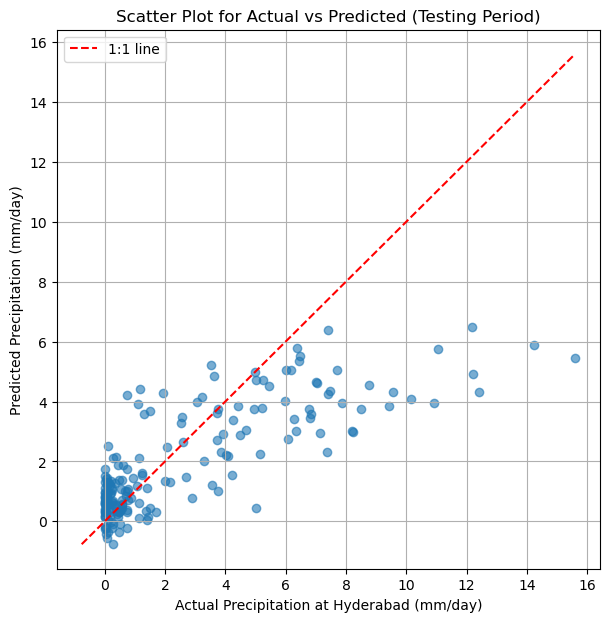

In [14]:
# Scatter Plot for Actual vs Predicted(Testing Period)
plt.figure(figsize=(7,7))
plt.scatter(Y_test, Y_test_pred, alpha=0.6)
# 1:1 line (perfect prediction)
lo = min(Y_test.min(), Y_test_pred.min())
hi = max(Y_test.max(), Y_test_pred.max())
plt.plot([lo, hi], [lo, hi], 'r--', label='1:1 line')
plt.xlabel("Actual Precipitation at Hyderabad (mm/day)")
plt.ylabel("Predicted Precipitation (mm/day)")
plt.title("Scatter Plot for Actual vs Predicted (Testing Period)")
plt.legend()
plt.grid(True)
plt.show()

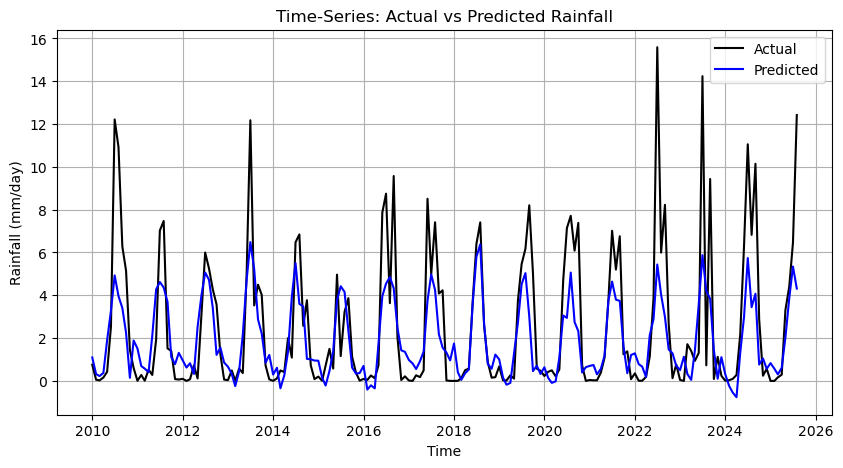

In [15]:
# Time Series plot for Actual vs Predicted Rainfall
plt.figure(figsize=(10, 5))
plt.plot(time_test, Y_test, label='Actual', color='black')
plt.plot(time_test, Y_test_pred, label='Predicted', color='blue')
plt.xlabel('Time')
plt.ylabel('Rainfall (mm/day)')
plt.title('Time-Series: Actual vs Predicted Rainfall')
plt.legend()
plt.grid(True)
plt.show()

## 11. Results and interpretation

The PCA regression achieves a test R² of approximately **0.53** and RMSE of approximately **2.27 mm/day**. The monthly climatology baseline performs better, with test R² of approximately **0.60** and RMSE of approximately **2.09 mm/day**. The baseline also performs better on the training metrics (R² 0.597 and RMSE 1.57 mm/day, compared with R² 0.532 and RMSE 1.69 mm/day for PCA regression).

This comparison indicates that the PCA regression does **not** outperform a simple month-of-year climatology. Because the model uses raw monthly values, part of its apparent skill is associated with the annual seasonal cycle. The retained PCs summarize much of the shared variability in the local atmospheric predictors, but that variability is not sufficiently aligned with rainfall to beat the climatology baseline in this experiment.

The testing plots also show underestimation of monsoon rainfall peaks. Linear regression is unbounded, so it can produce physically impossible negative precipitation estimates; 13 of the test-period predictions are negative.

**Conclusion:** The requested PCA-regression workflow was implemented and evaluated, but it did not demonstrate added predictive skill over monthly climatology. This limitation is reported rather than hidden.